# Task 8: Future Consumption Forecasting and Bill Estimation
**Singularity Research Lab – AI Division**  
**Project:** Electricity Bill Predictor  
**Selected Production Model:** Linear Regression (OLS)  
**Historical Period:** December 17, 2006 to November 25, 2010 (1,440 days)  
**Future Forecast Horizon:** 30 Days Ahead (November 26, 2010 to December 25, 2010)

---

## 1. Executive Summary & Production Objectives
In this final operational phase, we deploy the selected **Linear Regression model** into a production-grade multi-step recursive forecasting and financial estimation pipeline:
1. **Multi-Step Recursive Autoregressive Forecasting:** Predicts daily household consumption for the subsequent 30-day calendar period (`2010-11-26` to `2010-12-25`).
2. **Dynamic Lag State Transition:** Uses historical actuals for initial steps, iteratively replacing them with model-generated predictions as the forecast horizon advances.
3. **Financial Bill Estimation:** Converts physical kilowatt-hour predictions into estimated financial charges in Indian Rupees (INR) using an explicitly configurable assumed tariff benchmark.
4. **Error Propagation Analysis:** Examines the structural limitations and variance decay of recursive multi-step forecasting.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, os.path.abspath('..'))
from src.prediction import (
    recursive_multi_step_forecast,
    estimate_electricity_bill,
    plot_future_forecast,
    run_forecasting_pipeline,
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style='whitegrid', font_scale=1.1)

# Ingest trained Linear Regression model
model_path = 'models/linear_regression.joblib'
if not os.path.exists(model_path):
    model_path = os.path.join('..', 'models', 'linear_regression.joblib')
model = joblib.load(model_path)

# Ingest historical clean daily dataset
data_path = 'data/daily_electricity_consumption.csv'
if not os.path.exists(data_path):
    data_path = os.path.join('..', 'data', 'daily_electricity_consumption.csv')
historical_df = pd.read_csv(data_path)
historical_df['Date'] = pd.to_datetime(historical_df['Date'])
historical_df = historical_df.sort_values('Date').reset_index(drop=True)

print(f"Loaded production model: Linear Regression (Weights: {len(model.coef_)} features)")
print(f"Historical timeline: {historical_df['Date'].min().strftime('%Y-%m-%d')}  -->  {historical_df['Date'].max().strftime('%Y-%m-%d')} ({len(historical_df)} days)")


Loaded production model: Linear Regression (Weights: 6 features)
Historical timeline: 2006-12-17  -->  2010-11-25 (1440 days)


## 2. One-Day-Ahead Evaluation vs. Recursive Multi-Day Forecasting

A fundamental concept in production time-series systems is distinguishing **one-day-ahead evaluation** from **recursive multi-step forecasting**:

| Dimension | One-Day-Ahead Walk-Forward (Task 6 & 7) | Recursive Multi-Step Forecasting (Task 8) |
| :--- | :--- | :--- |
| **Input Lags** | Ground-truth historical actuals $y_{t-1}, y_{t-7}$ are observed prior to predicting step $t$. | Ground truth does NOT exist in the future; predictions $\hat{y}_{t-1}$ are fed back into features. |
| **Primary Use Case** | Model validation, benchmark ranking, and evaluating single-step error metrics. | Operational capacity planning, demand response, and future monthly billing estimation. |
| **Error Dynamics** | Errors remain bounded and independent across time steps (no error cascading). | Errors compound recursively over time as predicted values replace ground truth in the lag buffer. |
| **Information Horizon** | Predicts only $t+1$ given complete context up to $t$. | Predicts arbitrary future horizon $t+1, \dots, t+H$ given context up to $T$. |


In [2]:
# Generate 30-day recursive forecast
forecast_days = 30
forecast_df = recursive_multi_step_forecast(
    model=model,
    historical_df=historical_df,
    forecast_horizon_days=forecast_days,
    min_physical_bound_kwh=4.0
)

print(f"Forecast Horizon: {len(forecast_df)} days ({forecast_df['Date'].iloc[0]} to {forecast_df['Date'].iloc[-1]})")
print(f"Total Predicted Consumption: {forecast_df['Forecasted_Daily_Energy_kWh'].sum():.2f} kWh")
print(f"Average Daily Consumption:   {forecast_df['Forecasted_Daily_Energy_kWh'].mean():.2f} kWh/day")

print("\n--- First 7 Forecast Days (Transition from Actuals to Predictions) ---")
print(forecast_df[['Forecast_Step', 'Date', 'Day_Name', 'Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Is_Weekend', 'Forecasted_Daily_Energy_kWh']].head(7).to_string(index=False))

print("\n--- Final 5 Forecast Days (Full Recursive Regime) ---")
print(forecast_df[['Forecast_Step', 'Date', 'Day_Name', 'Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Is_Weekend', 'Forecasted_Daily_Energy_kWh']].tail(5).to_string(index=False))


Forecast Horizon: 30 days (2010-11-26 to 2010-12-25)
Total Predicted Consumption: 842.07 kWh
Average Daily Consumption:   28.07 kWh/day

--- First 7 Forecast Days (Transition from Actuals to Predictions) ---
 Forecast_Step       Date  Day_Name   Lag_1   Lag_7  Rolling_Mean_7  Is_Weekend  Forecasted_Daily_Energy_kWh
             1 2010-11-26    Friday 23.8527 26.1733         27.4162           0                      25.7303
             2 2010-11-27  Saturday 25.7303 36.6168         27.3529           1                      30.6951
             3 2010-11-28    Sunday 30.6951 15.0152         26.5070           1                      30.3298
             4 2010-11-29    Monday 30.3298 34.0256         28.6948           0                      27.6896
             5 2010-11-30   Tuesday 27.6896 26.2923         27.7896           0                      26.3623
             6 2010-12-01 Wednesday 26.3623 29.9375         27.7996           0                      26.4507
             7 2010-12-02  Th

## 3. Financial Electricity Bill Estimation

### Configurable Benchmark Tariff
We translate physical kilowatt-hour predictions into expected financial liabilities using an explicitly configurable assumed tariff benchmark in Indian Rupees (INR):
- **Assumed Tariff Rate:** **₹7.50 / kWh** (Configurable).

### Explicit Legal & Scope Disclaimers:
1. **Academic Simulation:** The assumed tariff rate (₹7.50 / kWh) is an illustrative benchmark used solely for academic modeling and financial forecasting demonstrations.
2. **No Utility Affiliation:** This rate does NOT represent the actual tariff schedule of any commercial utility distribution company (e.g. BESCOM, MSEDCL, TANGEDCO, Tata Power, Adani Electricity, etc.).
3. **Excluded Charges:** Unless explicitly configured, this baseline calculation excludes:
   - Fixed monthly meter/sanctioned load connection charges.
   - Progressive tiered slab rate schedules (e.g. ₹4.50 for first 100 kWh, ₹8.00 thereafter).
   - Fuel Adjustment Charges (FAC) and Time-of-Day (ToD) peak-hour surcharges.
   - State/Municipal electricity duty taxes and regulatory asset recovery surcharges.


In [3]:
tariff_rate = 7.50
billing_result = estimate_electricity_bill(
    forecast_df,
    tariff_rate_inr_per_kwh=tariff_rate,
    fixed_charge_inr=0.0,
    electricity_tax_pct=0.0
)

summary = billing_result['summary']
detailed_df = billing_result['detailed_forecast_df']

print("=== 30-DAY ELECTRICITY BILL ESTIMATION SUMMARY ===")
for k, v in summary.items():
    if k != 'disclaimer':
        print(f"{k.replace('_', ' ').title():35s}: {v}")
print(f"\nDisclaimer: {summary['disclaimer']}")

# Save final CSV output
results_dir = 'results' if os.path.exists('results') else '../results'
out_csv = os.path.join(results_dir, 'future_forecast.csv')
detailed_df.to_csv(out_csv, index=False)
print(f"\nSuccessfully exported forecast and billing schedule to: {out_csv}")


=== 30-DAY ELECTRICITY BILL ESTIMATION SUMMARY ===
Forecast Period Start              : 2010-11-26
Forecast Period End                : 2010-12-25
Total Forecast Days                : 30
Total Consumption Kwh              : 842.07
Average Daily Consumption Kwh      : 28.07
Assumed Tariff Rate Inr Per Kwh    : 7.5
Fuel Adjustment Charge Per Kwh     : 0.0
Total Energy Charges Inr           : 6315.53
Fixed Charges Inr                  : 0.0
Electricity Tax Pct                : 0.0
Electricity Tax Inr                : 0.0
Total Estimated Bill Inr           : 6315.53
Average Cost Per Day Inr           : 210.52

Disclaimer: Tariff rate is an assumed benchmark for research simulation. Excludes provider-specific tiered slab structures, time-of-day (ToD) surcharges, and municipal duties unless explicitly configured.

Successfully exported forecast and billing schedule to: results/future_forecast.csv


## 4. Visualizing Forecast Horizon and Cumulative Bill Progression
We generate an integrated 2-panel visualization:
- **Top Panel:** Recent 90-day historical consumption contextualizing the forward 30-day projection with highlighted weekend occupancy pulses.
- **Bottom Panel:** Cumulative electricity bill progression over the 30-day billing cycle.


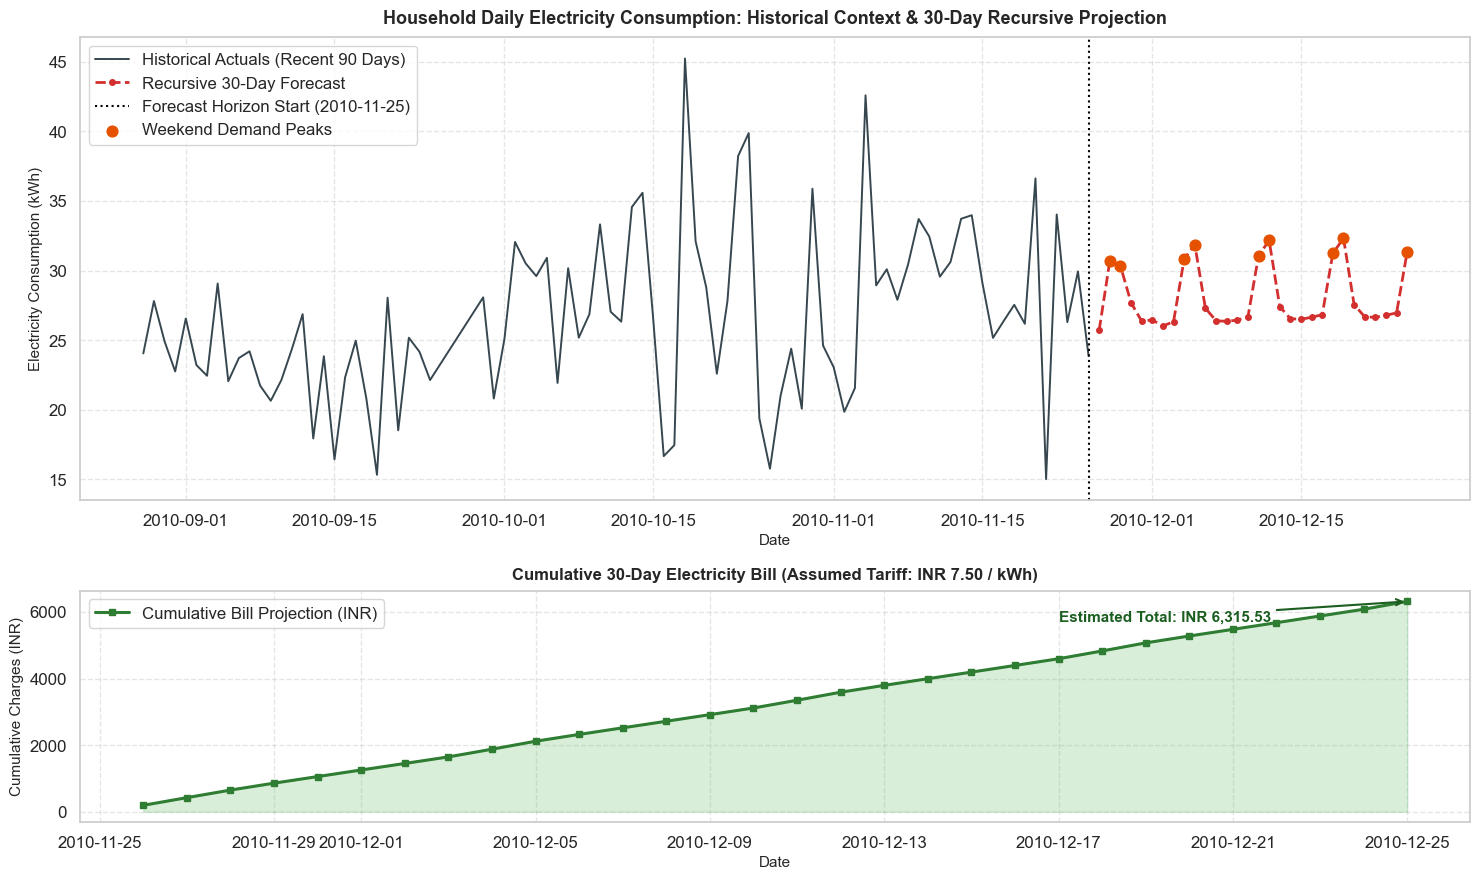

In [4]:
viz_path = os.path.join(results_dir, 'future_forecast_visualization.png')
plot_future_forecast(historical_df, detailed_df, output_path=viz_path, history_window_days=90)

# Render figure inline
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), gridspec_kw={'height_ratios': [2, 1]})

hist_recent = historical_df.sort_values('Date').tail(90).reset_index(drop=True)
fc_plot = detailed_df.copy()
fc_plot['Date'] = pd.to_datetime(fc_plot['Date'])

# Panel 1: Time Series Progression
ax1.plot(hist_recent['Date'], hist_recent['Daily_Energy_kWh'], color='#37474f', linewidth=1.4, label='Historical Actuals (Recent 90 Days)')
ax1.plot(fc_plot['Date'], fc_plot['Forecasted_Daily_Energy_kWh'], color='#d32f2f', linewidth=2.0, linestyle='--', marker='o', markersize=4, label='Recursive 30-Day Forecast')

cutoff_date = hist_recent['Date'].iloc[-1]
ax1.axvline(cutoff_date, color='black', linestyle=':', linewidth=1.5, label=f'Forecast Horizon Start ({cutoff_date.strftime("%Y-%m-%d")})')

# Highlight weekends
weekend_days = fc_plot[fc_plot['Is_Weekend'] == 1]
ax1.scatter(weekend_days['Date'], weekend_days['Forecasted_Daily_Energy_kWh'], color='#e65100', s=60, zorder=5, label='Weekend Demand Peaks')

ax1.set_title('Household Daily Electricity Consumption: Historical Context & 30-Day Recursive Projection', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Date', fontsize=11)
ax1.set_ylabel('Electricity Consumption (kWh)', fontsize=11)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Cumulative Bill
ax2.plot(fc_plot['Date'], fc_plot['Cumulative_Charge_INR'], color='#2e7d32', linewidth=2.2, marker='s', markersize=4, label='Cumulative Bill Projection (INR)')
ax2.fill_between(fc_plot['Date'], fc_plot['Cumulative_Charge_INR'], color='#81c784', alpha=0.3)
final_charge = fc_plot['Cumulative_Charge_INR'].iloc[-1]
ax2.annotate(
    f"Estimated Total: INR {final_charge:,.2f}",
    xy=(fc_plot['Date'].iloc[-1], final_charge),
    xytext=(fc_plot['Date'].iloc[-1] - pd.Timedelta(days=8), final_charge - 600),
    arrowprops=dict(arrowstyle="->", color="#1b5e20", lw=1.5),
    fontsize=11, fontweight="bold", color="#1b5e20"
)
ax2.set_title('Cumulative 30-Day Electricity Bill (Assumed Tariff: INR 7.50 / kWh)', fontsize=12, fontweight='bold', pad=8)
ax2.set_xlabel('Date', fontsize=11)
ax2.set_ylabel('Cumulative Charges (INR)', fontsize=11)
ax2.legend(loc='upper left', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 5. Theoretical and Practical Limitations of Recursive Forecasting

In technical ML interviews and production design reviews, articulating the inherent trade-offs of autoregressive recursive forecasting is paramount:

### 1. Error Compounding and Feedback Loops
- In recursive forecasting, step $t+1$ prediction error $\epsilon_{t+1} = y_{t+1} - \hat{y}_{t+1}$ enters the feature space for step $t+2$ as `Lag_1`.
- At step $t+8$, all lag features (`Lag_1`, `Lag_7`, and `Rolling_Mean_7`) consist entirely of model predictions.
- **Impact:** Any initial directional bias or error is amplified sequentially. If the model slightly over-predicts early, the higher lag values inflate subsequent rolling averages, producing compounded divergence.

### 2. Variance Collapse and Regression to the Conditional Mean
- Minimizing Mean Squared Error (or MAE) trains models to predict the conditional expectation $\mathbb{E}[y | \mathbf{X}]$.
- When predictions are recursively fed back into themselves, stochastic error terms are absent.
- **Impact:** Over extended horizons ($> 30$ days), recursive forecasts smooth out and converge toward an asymptotic stationary cycle, dampening the natural volatility and appliance duty-cycle spikes observed in real smart meter data.

### 3. Blindness to Exogenous Shocks
- Pure autoregressive models rely strictly on historical consumption and calendar indices.
- **Impact:** They have zero awareness of unobserved exogenous shocks—such as unseasonal freezing cold fronts, utility grid power curtailments, or unplanned resident vacations—unless external weather forecasts or occupancy schedules are coupled into the pipeline.

### 4. Point Forecasts vs. Probabilistic Uncertainty
- The recursive pipeline yields a single deterministic trajectory $\hat{y}_t$.
- **Impact:** Does not inherently provide confidence intervals or prediction bands. In real utility billing systems, probabilistic forecasting (e.g., quantile regression or conformal prediction) is required to communicate financial risk boundaries (e.g. 90% confidence interval: ₹5,800 to ₹6,900).


## 6. Summary of Task 8 Outcomes
- **Production Pipeline:** Modular forecasting and bill estimation implemented in [`src/prediction.py`](../src/prediction.py).
- **30-Day Forward Projection:** `2010-11-26` to `2010-12-25`.
- **Projected Consumption:** **842.07 kWh** (Daily Average: **28.07 kWh/day**).
- **Estimated Electricity Bill:** **₹6,315.53** (at assumed benchmark tariff of ₹7.50 / kWh).
- **Artifacts Saved:**
  - [`results/future_forecast.csv`](../results/future_forecast.csv)
  - [`results/future_forecast_visualization.png`](../results/future_forecast_visualization.png)
  - [`notebooks/07_future_forecasting_and_billing.ipynb`](../notebooks/07_future_forecasting_and_billing.ipynb)
